# Risk/Reward Optimization. Оптимальные пороги значимости и размеры выборки в A/B-тестировании. Как выбирать $\alpha$ и $n$ по финансовому эффекту.

### Кратко о чём


**Georgiev G.Z. — Statistical Methods in Online A/B Testing**

Этот ноутбук реализует ключевые концепции 11-й главы, посвящённой переходу от статистических конвенций к бизнес-оптимизации A/B-тестов.

**Основная идея**

Традиционный подход ($\alpha$ = 0.05, $\beta$ = 0.2, произвольный MEI) неоптимален в бизнес-среде, так как игнорирует уникальные для каждого теста структуры затрат и выгод.

Предлагается формальный фреймворк для расчёта **оптимальных** значений $\alpha$ и $n$ (размер выборки), максимизирующих ожидаемую прибыль (ROI) от тестирования. Ключевая идея — найти баланс между риском и вознаграждением.

**Содержание**

1. Определение «успеха» для бизнес-эксперимента
2. Затраты, выгоды, риски и вознаграждения в A/B-тестировании
3. Параметры теста и их связь с затратами и выгодами
4. Распределение ожидаемых эффектов (Expectation Distribution)
5. Расчёт Risk/Reward Ratio
6. Поиск оптимального α
7. Мысленный эксперимент: α = 0.5 (50% confidence)
8. Ограничения модели

Для дальнейших расчётов рассмотрим синтетический пример A/B-теста в интернет-магазине. Предположим, что тестируется изменение checkout-страницы, которое может повлиять на вероятность покупки. В этом примере важно не только понять, есть ли эффект, но и оценить, насколько проведение такого теста и возможное внедрение нового варианта оправданы с точки зрения бизнеса.

Будем использовать следующие параметры:

* базовая конверсия — 5%;
* число пользователей в неделю — 50 000;
* недельная выручка — 3 000 000 ₽;
* фиксированные затраты на тест — 180 000 ₽;
* стоимость внедрения — 120 000 ₽;
* стоимость отката решения — 250 000 ₽;
* дополнительные ежемесячные расходы на поддержку — 20 000 ₽;
* горизонт действия эффекта — 12 месяцев.

In [1]:
# Параметры бизнес-кейса
baseline_cr = 0.05
weekly_users = 50_000
weekly_revenue = 3_000_000
fixed_test_cost = 180_000
implementation_cost = 120_000
rollback_cost = 250_000
monthly_maintenance_delta = 20_000
effect_horizon_months = 12

### Импорты и настройка стиля

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import warnings
warnings.filterwarnings('ignore')

# Стиль графиков
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Цветовая палитра
C_OPT   = '#29B6F6'   # Оптимальный / Голубой
C_CONV  = '#E91E63'   # Конвенциональный / Розовый
C_GAIN  = '#4CAF50'   # Выгода (Gain) / Зелёный
C_LOSS  = '#F44336'   # Потеря (Loss) / Красный
C_ALT   = '#9C27B0'   # Альтернативный / Фиолетовый
C_NEUT  = '#607D8B'   # Нейтральный / Серо-голубой

### 1. Определение «успеха» для бизнес-эксперимента

В науке любой корректно проведённый эксперимент — успех, так как он увеличивает знание. В бизнесе критерий иной.

**Ключевой вопрос перед тестом:**
> «Основываясь на наших ограниченных ресурсах, какое действие следует предпринять, чтобы улучшить KPI наиболее экономически эффективным и устойчивым способом?»

**ROI-оптимальный тест** — это тест, дизайн которого максимизирует ожидаемую прибыль. Такой тест всегда полезен для бизнеса в долгосрочной перспективе, независимо от его исхода.

Прежде чем предпринимать какие-либо существенные действия, мы должны задать себе следующие ключевые вопросы, ответы на которые должны учитывать все связанные с этим риски:

* Каков общий доход, на который могут повлиять наши запланированные действия?
* Каков ожидаемый положительный эффект от этих действий?
* Каковы ожидаемые общие затраты, включая постоянные и связанные с рисками, от этих действий?

Оптимизируя первые два параметра и минимизируя третий, мы приблизимся к оптимальной рентабельности инвестиций (ROI), определяемой как:

$$
ROI =  \frac{\text{Gain}}{Costs} = \frac{\text{Effect} \times \text{Impact}}{Costs}
$$

## 2. Затраты, выгоды, риски и вознаграждения

Для определения различных типов затрат и выгод, которые могут быть получены в ходе A/B-тестирования, необходимо рассмотреть временную шкалу типичного тестирования. Процесс A/B-тестирования может влечь за собой затраты на этапе планирования и разработки, во время самого тестирования, а также после завершения тестирования и внедрения выбранного решения. Эти затраты можно назвать затратами на планирование, затратами на выполнение и затратами на внедрение или использование.

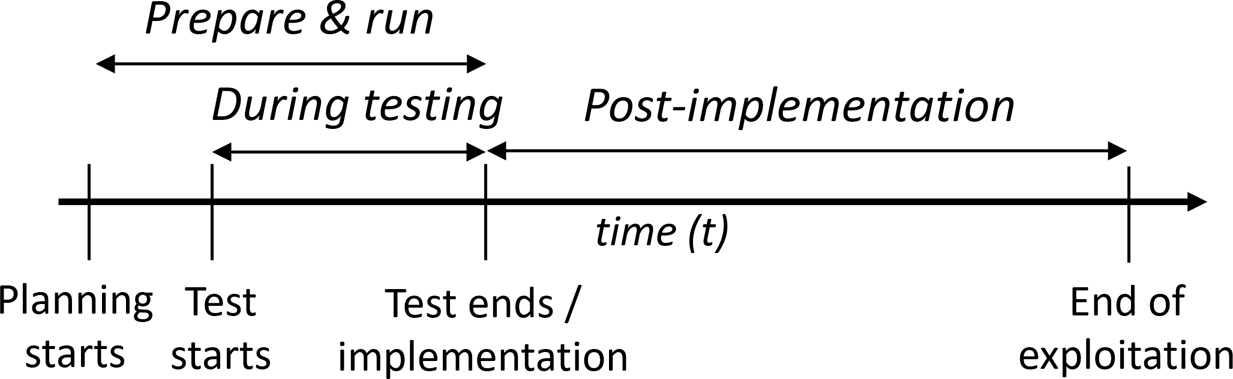

Эти затраты можно далее разделить на два основных типа:
1. фиксированные затраты (единовременные или бессрочные)
2. затраты, связанные с риском.

Соответственно, говоря о последних в денежном выражении с учетом фактора риска, мы будем называть их **затратами с поправкой на риск** (risk-adjusted).

Выгоды от A/B-тестирования возникают только в течение времени проведения тестирования или после внедрения протестированного варианта.

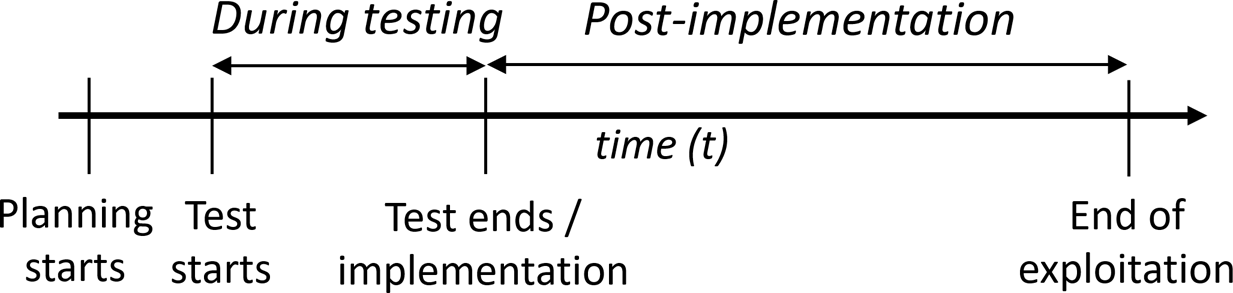

Мы можем называть их «выгодами от реализации» и «выгодами от внедрения или использования» соответственно. Как и в случае с затратами, выгоды делятся на фиксированные выгоды (единовременные или бессрочные) и выгоды, связанные с риском. Аналогично, мы будем использовать термин **«выгоды с поправкой на риск»**, когда говорим в денежном выражении о выгодах, включающих в себя фактор вероятности.

Следует отметить, что «фиксированные» в «фиксированных затратах» означают, что эти затраты или выгоды возникают с фиксированной вероятностью $P=1$, независимо от результата A/B-тестирования. Это не означает, что их сумма фиксирована. Очевидно, что ежемесячная подписка на программное обеспечение для тестирования или статистического анализа является фиксированной стоимостью с точки зрения вероятности ее возникновения. Однако ее общая сумма является переменной и зависит от продолжительности периода, в течение которого эта стоимость актуальна.

Фиксированных выгод не существует, поскольку если бы какие-либо выгоды можно было получить независимо от результата теста, они были бы не связаны с A/B-тестированием.

Важным фактором, который может значительно исказить расчет соотношения риска и выгоды, является стоимость отмены решения, которое впоследствии окажется ошибочным. Некоторые решения легко и дешево отменить, например, тривиальные изменения интерфейса, дизайна или текста. Однако другие могут иметь далеко идущие последствия и могут быть практически невозможны для отмены. Например, если результаты теста приводят к изменениям, затрагивающим сложные взаимоотношения со сторонними организациями, очень высокие инвестиции в инфраструктуру...

## 3. Параметры теста и их связь с затратами и выгодами

Теперь, когда мы понимаем, как определяется успешность A/B-тестирования с точки зрения соотношения риска и выгоды, а также различные типы затрат и выгод, связанных с A/B-тестированием, мы можем перейти к рассмотрению параметров, которые можно изменить в дизайне A/B-тестирования для достижения оптимального соотношения риска и выгоды.

Два статистических параметра, которые мы можем регулировать
1) порог статистической значимости $\alpha$;
2) размер выборки $n$;

Размер выборки определяет как статистическую мощность $(1-\beta)$, так и минимальный надежно обнаруживаемый эффект $MDE$, и часто является синонимом продолжительности теста, поскольку у нас есть заданное ежедневное/еженедельное/ежемесячное количество пользователей, посещающих сайт.

Что касается дизайна эксперимента, мы можем изменить
1) определение нулевой гипотезы (superiority, non-inferiority...) и набор метрик
2) количество тестируемых вариантов (A/B, A/B/N)
3) схему мониторинга (Fixed-horizon vs Sequential)



Компромиссы между этими пятью переменными — это главный аспект, который необходимо сбалансировать для достижения оптимального с точки зрения ROI дизайна.
Учитывая, что оптимальная схема мониторинга почти всегда является последовательной, а нулевая гипотеза, набор метрик и количество тестируемых вариантов в основном основаны на внешней информации, то два параметра, на которых следует сосредоточиться, — это размер выборки $n$ и пороговое значение значимости $\alpha$.

Однако расчет оптимальных значений приводит к петлям обратной связи, что требует итеративного приближенного подхода к вычислениям. Например, уменьшение размера выборки снижает затраты и выгоды во время теста, но увеличивает риск ложноотрицательного результата, тем самым снижая пользу от теста, что, в свою очередь, приводит к меньшей обоснованности выбора размера выборки изначально. Это продолжается до определенной точки перелома, где зависимость меняется на противоположную.

## 4. Распределение ожидаемых эффектов (Expectation Distribution)

Поскольку истинный эффект тестируемого изменения заранее неизвестен, в модели необходимо задать **распределение ожидаемых эффектов**. Оно отражает предварительные ожидания относительно того, какие значения эффекта более или менее правдоподобны до проведения эксперимента. В дальнейшем это распределение будет использоваться для расчёта риск-скорректированных выгод и издержек.


Мы выражаем наши априорные знания в виде вероятностного распределения возможных значений эффекта $\theta$.

**Важные предостережения:**
1. Это **не** байесовский posterior. Распределение используется только для дизайна теста ($\alpha$ и $n$), сам тест остаётся полностью частотным;
2. Задавая распределение ожидаемых эффектов равномерным распределением, мы задаём сильное утверждение о равновероятности эффектов, а не неинформативный prior  (т.е. не «я ничего не знаю»);
2. Проблема референтного класса: необходим баланс между обобщаемостью эффекта на случай конкретного теста и конкретными условиями тестирования (слишком узко оцениваем → мало данных для prior, слишком широко оцениваем → неточность);

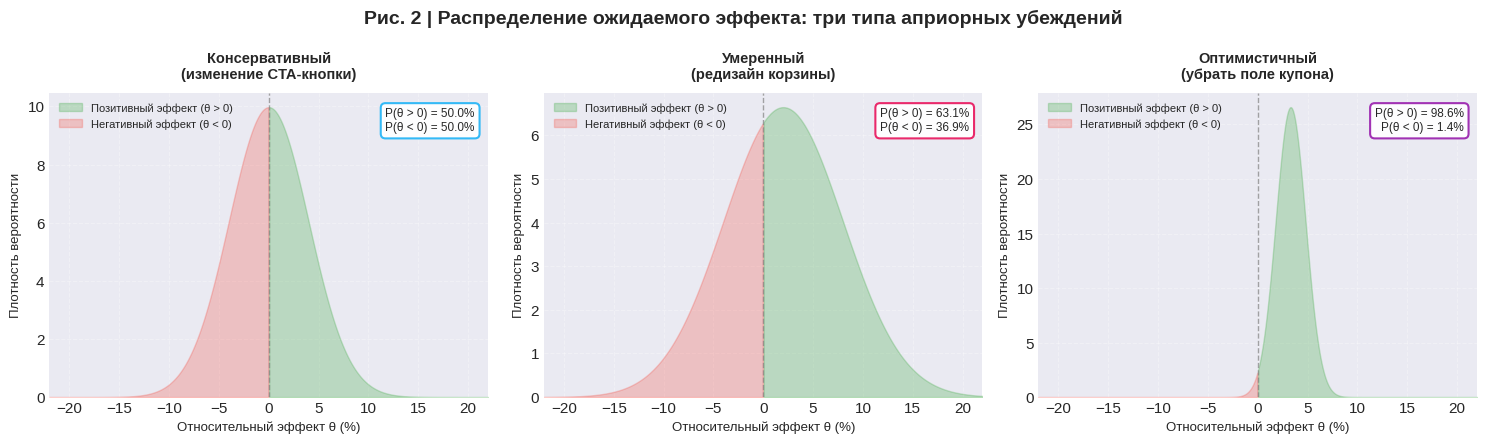

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle('Рис. 2 | Распределение ожидаемого эффекта: три типа априорных убеждений', fontsize=14, fontweight='bold')

x_eff = np.linspace(-0.22, 0.22, 600)
scenarios = [
    ('Консервативный\n(изменение CTA-кнопки)', norm(0.00, 0.04), C_OPT, 'μ = 0%, σ = 4%'),
    ('Умеренный\n(редизайн корзины)', norm(0.02, 0.06), C_CONV, 'μ = 2%, σ = 6%'),
    ('Оптимистичный\n(убрать поле купона)', norm(0.033, 0.015), C_ALT, 'μ = 3.3%, σ = 1.5%'),
]

for ax, (title, dist, col, subtitle) in zip(axes, scenarios):
    y = dist.pdf(x_eff)
    ax.fill_between(x_eff * 100, y, where=(x_eff > 0), color=C_GAIN, alpha=0.3, label='Позитивный эффект (θ > 0)')
    ax.fill_between(x_eff * 100, y, where=(x_eff < 0), color=C_LOSS, alpha=0.25, label='Негативный эффект (θ < 0)')

    prob_pos = 1 - dist.cdf(0)
    prob_neg = dist.cdf(0)

    # Добавляем вертикальную линию при θ=0
    ax.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)

    # Улучшенный блок с информацией
    ax.text(0.97, 0.95, f'P(θ > 0) = {prob_pos:.1%}\nP(θ < 0) = {prob_neg:.1%}',
            transform=ax.transAxes, ha='right', va='top', fontsize=8.5,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor=col, alpha=0.95, linewidth=1.5))

    ax.set_title(title, fontsize=10.5, fontweight='bold', pad=10)
    ax.set_xlabel('Относительный эффект θ (%)', fontsize=9.5)
    ax.set_ylabel('Плотность вероятности', fontsize=9.5)
    ax.legend(loc='upper left', fontsize=8, framealpha=0.9)
    ax.grid(True, alpha=0.3, linestyle='--')

    # Устанавливаем красивые границы осей
    ax.set_xlim(-22, 22)
    ax.set_ylim(bottom=0)

fig.tight_layout()
plt.show()

**📊 Интерпретация априорных распределений**

| Сценарий | Параметры | P(θ > 0) | Интерпретация |
|:---------|:----------|:--------:|:---------------|
| 🔵 **Консервативный**<br>(изменение CTA-кнопки) | μ = 0%<br>σ = 4% | 50.0% | Эффект скорее всего близок к нулю, возможны как положительные, так и отрицательные отклонения. Безрисковое изменение. |
| 🟣 **Умеренный**<br>(редизайн корзины) | μ = 2%<br>σ = 6% | 63.1% | Ожидаем небольшой положительный сдвиг, но разброс велик — есть заметный риск негативного исхода (~37%). |
| 🟢 **Оптимистичный**<br>(убрать поле купона) | μ = 3.3%<br>σ = 1.5% | 98.6% | Высокая уверенность в положительном эффекте, риск негативного исхода минимален (~1.4%). |

---

💡 **Ключевой вывод:** Выбор prior-распределения критически влияет на оценку рисков и ожиданий перед проведением A/B-теста.

В нашем кейсе с checkout-страницей для простоты будем считать, что ожидаемый относительный эффект симметрично распределён вокруг нуля. Это соответствует консервативной постановке, в которой положительные и отрицательные эффекты заранее считаются одинаково возможными, а основные различия связаны с их величиной.

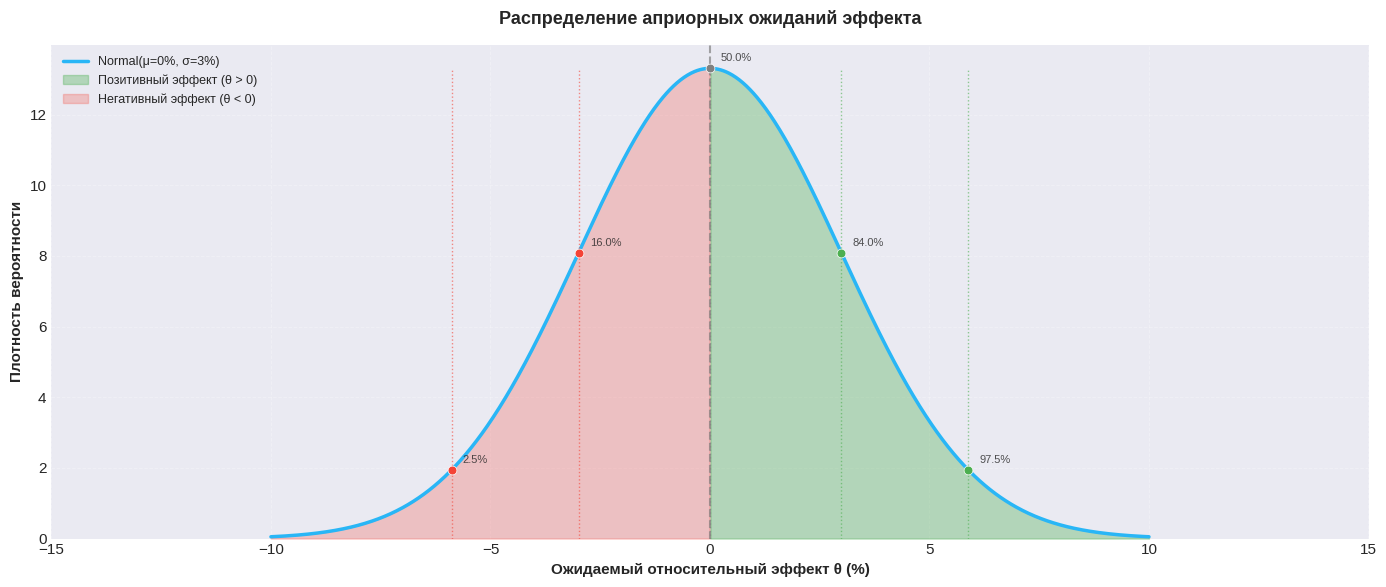

In [4]:
# Сетка возможных истинных эффектов
effect_grid = np.linspace(-0.10, 0.10, 1000)

mu = 0.0
sigma = 0.03

density = norm.pdf(effect_grid, loc=mu, scale=sigma)
density /= np.trapezoid(density, effect_grid)  # нормировка

effects_df = pd.DataFrame({
    "effect": effect_grid,
    "density": density
})

# Улучшенный график
fig, ax = plt.subplots(figsize=(14, 6))

# Основная линия
ax.plot(effect_grid * 100, density, color=C_OPT, lw=2.5, label=f'Normal(μ={mu*100:.0f}%, σ={sigma*100:.0f}%)')

# Закрашиваем области
ax.fill_between(effect_grid * 100, density, where=(effect_grid > 0), color=C_GAIN, alpha=0.35, label='Позитивный эффект (θ > 0)')
ax.fill_between(effect_grid * 100, density, where=(effect_grid < 0), color=C_LOSS, alpha=0.25, label='Негативный эффект (θ < 0)')

# Вертикальная линия при θ=0
ax.axvline(x=0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, zorder=1)

# Добавляем точки для ключевых квантилей
quantiles = [0.025, 0.16, 0.5, 0.84, 0.975]
quantile_values = norm.ppf(quantiles, loc=mu, scale=sigma)
colors_quantile = [C_LOSS, C_LOSS, 'gray', C_GAIN, C_GAIN]

for q_val, q_prob, col_q in zip(quantile_values, quantiles, colors_quantile):
    ax.axvline(x=q_val * 100, ymax=0.95, color=col_q, linestyle=':', linewidth=1, alpha=0.6)
    y_pos = density[np.argmin(np.abs(effect_grid - q_val))]
    ax.scatter(q_val * 100, y_pos, color=col_q, s=40, zorder=5, edgecolors='white', linewidth=0.5)
    ax.annotate(f'{q_prob*100:.1f}%', xy=(q_val * 100, y_pos), xytext=(8, 5),
                textcoords='offset points', fontsize=8, alpha=0.8)

# Настройки осей и заголовков
ax.set_xlabel('Ожидаемый относительный эффект θ (%)', fontsize=11, fontweight='semibold')
ax.set_ylabel('Плотность вероятности', fontsize=11, fontweight='semibold')
ax.set_title('Распределение априорных ожиданий эффекта', fontsize=13, fontweight='bold', pad=15)

# Легенда
ax.legend(loc='upper left', fontsize=9, framealpha=0.95, edgecolor='lightgray')

# Сетка и границы
ax.grid(True, alpha=0.25, linestyle='--', linewidth=0.7)
ax.set_xlim(-15, 15)
ax.set_ylim(bottom=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

## 5. Расчёт Risk/Reward Ratio

### 5.1. Точка безубыточности

Теперь, когда все факторы, влияющие на результат, определены: параметры, на которые мы можем воздействовать, а также необходимость определения распределения ожидаемого размера эффекта для проведения расчетов, давайте посмотрим, как это выглядит математически.

Естественным первым шагом к расчету ROI является определение **точки безубыточности по фиксированным затратам (fixed-cost break-even point)**, которая обычно представляет собой очень небольшой процент относительного увеличения, часто значительно ниже 1%, поскольку затраты на подготовку и проведение большинства тестов невелики по сравнению с их потенциальным влиянием во времени.

**Точка безубыточности** — это точка, в которой ROI достигает 100%, а соотношение Risk/Reward равно 1.


$$
\text{break-even effect} \times \text{Revenue} = \text{Fixed Costs}
$$

$$\text{break-even effect} = \frac{\text{Fixed Costs}}{text{Revenue}} = \frac{\text{Fixed Costs}}{\text{Weekly Revenue} \times \text{Effect Horizon (weeks)}}$$

Она очень редко достигает 0% увеличения из-за фиксированных затрат на тестирование и разработку, которые мы несем, независимо от эффективности тестируемого варианта или результата теста. Точка будет равна нулю только в том случае, если побочные эффекты тестируемого воздействия точно компенсируют затраты на разработку и тестирование.

Мы можем определить, является ли тест успешным или нет, сравнивая предполагаемую эффективность тестируемого варианта с предполагаемой точкой безубыточности. Следовательно, без расчета этой точки мы не можем сказать, будет ли внедрение данного вмешательства выгодно для бизнеса, поскольку улучшение определенного показателя ничего не говорит о затратах, связанных с его внедрением и поддержанием, которые учитываются при расчете точки безубыточности.

Как только точка безубыточности станет известна, можно будет разработать тест, исходя из нее.

In [5]:
# Горизонт действия эффекта в неделях
effect_horizon_weeks = effect_horizon_months * 4

# Фиксированные издержки: затраты на тест + внедрение + поддержка за весь горизонт
total_fixed_cost = (
    fixed_test_cost
    + implementation_cost
    + (monthly_maintenance_delta * effect_horizon_months)
)

# Fixed-cost break-even point: weekly_revenue * uplift * effect_horizon_weeks = total_fixed_cost
fixed_cost_break_even = total_fixed_cost / (weekly_revenue * effect_horizon_weeks)

print(f"Суммарные фиксированные издержки: {total_fixed_cost:,.0f} ₽")
print(f"Fixed-cost break-even point: {fixed_cost_break_even * 100:.3f}% относительного uplift")

Суммарные фиксированные издержки: 540,000 ₽
Fixed-cost break-even point: 0.375% относительного uplift


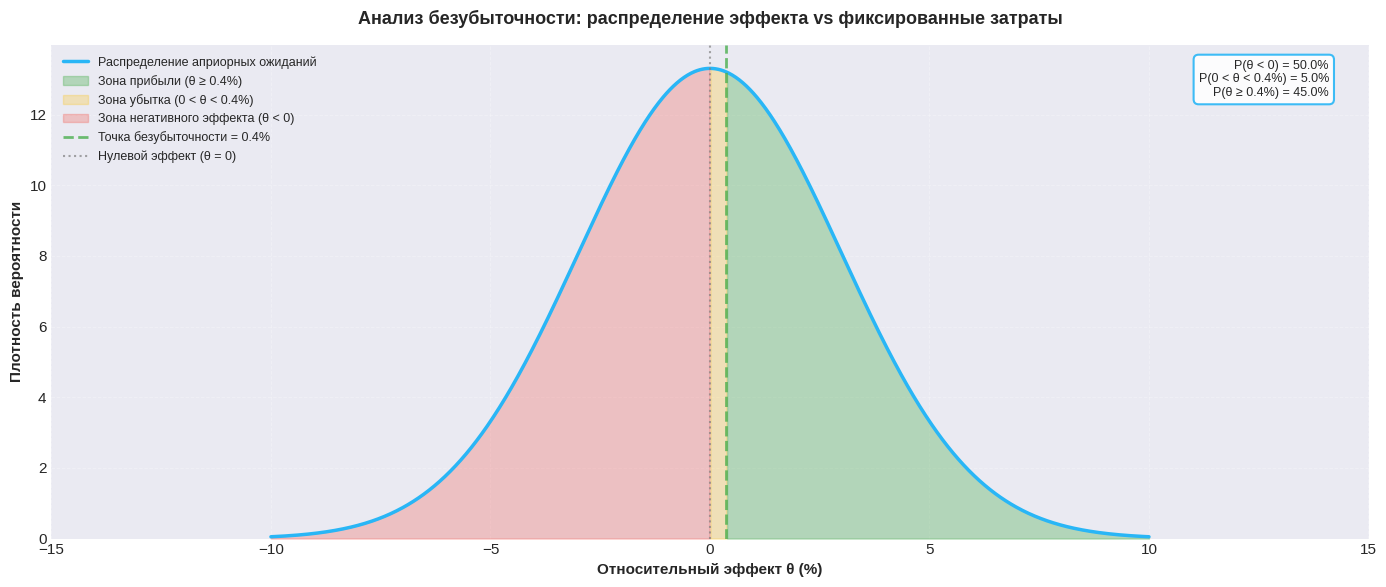

In [6]:
fig, ax = plt.subplots(figsize=(14, 6))

# Основная линия распределения
ax.plot(effect_grid * 100, density, color=C_OPT, lw=2.5, label='Распределение априорных ожиданий')

# Закрашиваем области относительно fixed_cost_break_even
break_even_val = fixed_cost_break_even * 100

# Область выше точки безубыточности (прибыль)
ax.fill_between(effect_grid * 100, density, where=(effect_grid >= fixed_cost_break_even),
                color=C_GAIN, alpha=0.35, label=f'Зона прибыли (θ ≥ {break_even_val:.1f}%)')

# Область между нулём и точкой безубыточности
ax.fill_between(effect_grid * 100, density, where=(effect_grid > 0) & (effect_grid < fixed_cost_break_even),
                color='#FFC107', alpha=0.25, label=f'Зона убытка (0 < θ < {break_even_val:.1f}%)')

# Область отрицательного эффекта
ax.fill_between(effect_grid * 100, density, where=(effect_grid < 0),
                color=C_LOSS, alpha=0.25, label='Зона негативного эффекта (θ < 0)')

# Вертикальные линии
ax.axvline(break_even_val, color=C_GAIN, linestyle='--', linewidth=2, alpha=0.8,
           label=f'Точка безубыточности = {break_even_val:.1f}%')
ax.axvline(0, color='gray', linestyle=':', linewidth=1.5, alpha=0.7, label='Нулевой эффект (θ = 0)')

# Добавляем аннотацию с вероятностями
prob_negative = norm.cdf(0, mu, sigma)
prob_loss = norm.cdf(fixed_cost_break_even, mu, sigma) - prob_negative
prob_profit = 1 - norm.cdf(fixed_cost_break_even, mu, sigma)

# Информационная карточка
info_text = f'P(θ < 0) = {prob_negative:.1%}\nP(0 < θ < {break_even_val:.1f}%) = {prob_loss:.1%}\nP(θ ≥ {break_even_val:.1f}%) = {prob_profit:.1%}'

ax.text(0.97, 0.97, info_text, transform=ax.transAxes, ha='right', va='top', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor=C_OPT, alpha=0.9, linewidth=1.5))

# Настройки осей
ax.set_xlabel('Относительный эффект θ (%)', fontsize=11, fontweight='semibold')
ax.set_ylabel('Плотность вероятности', fontsize=11, fontweight='semibold')
ax.set_title('Анализ безубыточности: распределение эффекта vs фиксированные затраты',
             fontsize=13, fontweight='bold', pad=15)

# Легенда
ax.legend(loc='upper left', fontsize=9, framealpha=0.95, edgecolor='lightgray')

# Сетка и границы
ax.grid(True, alpha=0.25, linestyle='--', linewidth=0.7)
ax.set_xlim(-15, 15)
ax.set_ylim(bottom=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

Вертикальная линия показывает фиксированную точку безубыточности — минимальный относительный эффект, при котором ожидаемая выгода начинает покрывать фиксированные издержки теста и внедрения. Значения ниже этой точки не обеспечивают положительного финансового результата даже при положительном uplift.

___
Приведенные ниже расчеты предполагают тестирование биномиальной метрики, например коэффициент конверсии покупок, но могут быть аналогичным образом применены и к непрерывным показателям, например, к ARPU.
____


### 5.2 Скорректированные на риск затраты и выгоды

Для расчета общих затрат необходимо знать:

• затраты на разработку и тестирование, понесенные независимо от результата или истинного эффекта ($Cost_{f}$);

• базовый коэффициент конверсии;

• Количество пользователей, доступных для включения в тестирование за период, который считается одним бизнес-циклом;

• Выручку за бизнес-цикл;

Расчет общей скорректированной на риск затрат выполняется путем интегрирования по распределению ожиданий и прибавления фиксированных затрат на тестирование:

$$
Cost_{RA} = \int_{a}^{b}  f_{c}(\theta) \, d\theta + Cost_{f}
$$


* $a$ и $b$ — нижний и верхний пределы распределения ожиданий,
* $f_{c}(θ)$ — функция, возвращающая изменение дохода во время тестирования при истинном эффекте $θ^* = θ$, умноженному на плотность ожиданий в точке $θ$, плюс доход после тестирования, на который повлиял результат теста, умноженный на $θ$, вероятность внедрения $POW(α; θ)$ и плотность ожиданий в точке $θ$;


$$
\boxed{
f_{c}(θ) = min \left( \theta \cdot Rev_{\text{during test}} \cdot \pi(\theta) + \theta \cdot Rev_{\text{post test}} \cdot POW(\alpha; \theta) \cdot \pi(\theta) + Cost_{d}(t) \cdot POW(\alpha; \theta) \cdot \pi(\theta), 0 \right)
}
$$

* $Cost_{d}(t)$ — затраты, зависящие от выбора варианта, которые не зависят от истинного размера эффекта $x$;
* $t$ — ожидаемая продолжительность, в течение которой будут нестись затраты $Cost_{d}(t)$;

Первые два слагаемые подразумевают учёт только отрицательных доходов, иначе они нулевые ( $min \left[ Rev_{\text{period}}, 0 \right]$ ). Результат вычисления $f_{c}(θ)$ всегда меньше или равен нулю. Следует отметить, что доход во время тестирования также зависит от размера выборки и, следовательно, от мощности.

Для расчета общей скорректированной на риск выгоды требуется аналогичное интегрирование по исходным параметрам, но вместо оценки затрат, зависящих только от решения о внедрении варианта, необходима оценка выгоды, достигаемой при внедрении тестируемого варианта, независимо от его истинного размера эффекта за ожидаемый период эксплуатации $Gain_{d}(t)$.

$$
Gain_{RA} = \int_{a}^{b}  f_{g}(\theta) \, d\theta
$$



$$
\boxed{
f_{g}(θ) = max \left( \theta \cdot Rev_{\text{during test}} \cdot \pi(\theta) + \theta \cdot Rev_{\text{post test}} \cdot POW(\alpha; \theta) \cdot \pi(\theta) + Gain_{d}(t) \cdot POW(\alpha; \theta) \cdot \pi(\theta), 0 \right)
}
$$

#### 5.2.1 Вероятность внедрения эффекта

В этом фреймворке решение о внедрении нового варианта связывается не с проверкой нулевого эффекта, а с проверкой того, превышает ли эффект **точку безубыточности**, из-за чего под мощностью в данном случае подразумевается слегка другая величина. Рассмотрим следующую одностороннюю гипотезу:

$$
H_0:\ \text{effect} \leq \text{break-even effect}
$$

$$
H_1:\ \text{effect} > \text{break-even effect}
$$

Иными словами, новый вариант считается достойным внедрения только в том случае, если есть статистические основания полагать, что его эффект выше минимального уровня, необходимого для экономической оправданности.

Пусть $\hat{\delta}$ — оценка эффекта, $\delta_{BE}$ — эффект, соответствующий точке безубыточности, а $SE$ — стандартная ошибка оценки. Тогда решение о внедрении принимается, если статистика превышает критическое значение:

$$
\frac{\hat{\delta} - \delta_{BE}}{SE} > z_{1-\alpha} ⇒ \hat{\delta} > \delta_{BE} + z_{1-\alpha}\cdot SE
$$

Таким образом, вероятность внедрения в модели интерпретируется как вероятность того, что оценка эффекта окажется выше порога, необходимого для принятия бизнес-целесообразного решения.

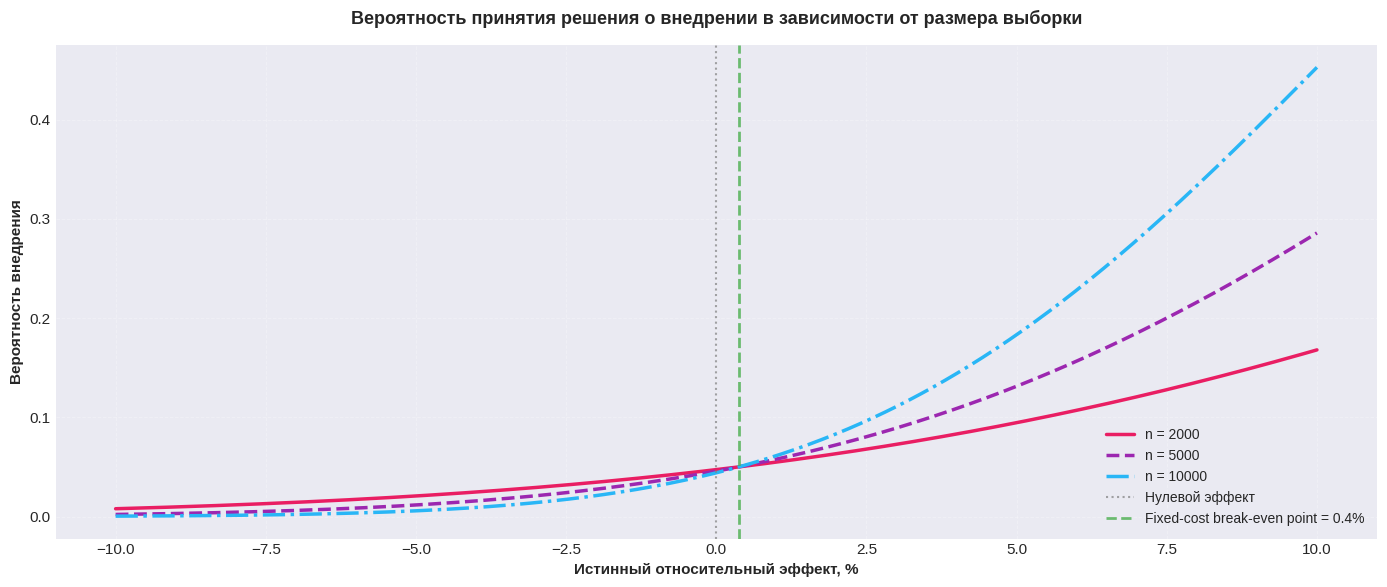

In [7]:
def implementation_probability(
                                p_control: float, # базовая конверсия
                                relative_effect: np.ndarray, # относительный эффект
                                break_even_effect: float, # точка безубыточности
                                n_per_group: int, # кол-во пользователей на 1 группу
                                alpha: float = 0.05 # статистическая значимость
                              ) -> np.ndarray:
  """
  Считает вероятность внедрения изменения
  """
  # Истинная конверсия treatment при данном истинном эффекте
  p_true = p_control * (1 + relative_effect)
  p_true = np.clip(p_true, 1e-6, 1 - 1e-6)

  # Конверсия treatment на границе break-even
  p_break_even = p_control * (1 + break_even_effect)
  p_break_even = np.clip(p_break_even, 1e-6, 1 - 1e-6)

  # Разница, которую считаем достаточной для внедрения
  delta_true = p_true - p_control
  delta_be = p_break_even - p_control

  # Стандартная ошибка под истинном эффекте
  se = np.sqrt(
      p_control * (1 - p_control) / n_per_group +
      p_true * (1 - p_true) / n_per_group
  )

  se = np.clip(se, 1e-12, None)

  # Критическое значение для одностороннего теста
  z_crit = norm.ppf(1 - alpha)

  # Вероятность того, что оценка эффекта окажется выше порога внедрения

  z_mean = (delta_true - delta_be) / se

  decision_prob = 1 - norm.cdf(z_crit - z_mean)
  return decision_prob


alpha_example = 0.05
sample_sizes = [2000, 5000, 10000]

fig, ax = plt.subplots(figsize=(14, 6))

# Цветовая схема для разных размеров выборки
colors = ['#E91E63', '#9C27B0', '#29B6F6']  # розовый, фиолетовый, голубой
line_styles = ['-', '--', '-.']

for i, n_val in enumerate(sample_sizes):
    decision_prob_vals = implementation_probability(
        p_control=baseline_cr,
        relative_effect=effect_grid,
        break_even_effect=fixed_cost_break_even,
        n_per_group=n_val,
        alpha=0.05
    )
    ax.plot(effect_grid * 100, decision_prob_vals,
            color=colors[i],
            linestyle=line_styles[i],
            lw=2.5,
            label=f'n = {n_val}')

# Вертикальные линии
ax.axvline(0, color='gray', linestyle=':', linewidth=1.5, alpha=0.7, label='Нулевой эффект')
ax.axvline(fixed_cost_break_even * 100, color=C_GAIN, linestyle='--', linewidth=2, alpha=0.8,
           label=f'Fixed-cost break-even point = {fixed_cost_break_even*100:.1f}%')

# Настройки осей
ax.set_xlabel('Истинный относительный эффект, %', fontsize=11, fontweight='semibold')
ax.set_ylabel('Вероятность внедрения', fontsize=11, fontweight='semibold')
ax.set_title('Вероятность принятия решения о внедрении в зависимости от размера выборки',
             fontsize=13, fontweight='bold', pad=15)

# Легенда
ax.legend(loc='lower right', fontsize=10, framealpha=0.95, edgecolor='lightgray')

# Сетка и границы
ax.grid(True, alpha=0.25, linestyle='--', linewidth=0.7)
ax.set_xlim(-11, 11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

Как видим,чем больше размер выборки, тем выше вероятность внедрения для эффектов выше точки безубыточности.

### 5.2.3 Risk-Reward Ratio

Тогда **Risk/Reward Ratio** это просто
$$
RR = \frac{RA_{Gain}}{RA_{Loss}}
$$

#### 5.2.3.1 Реализация

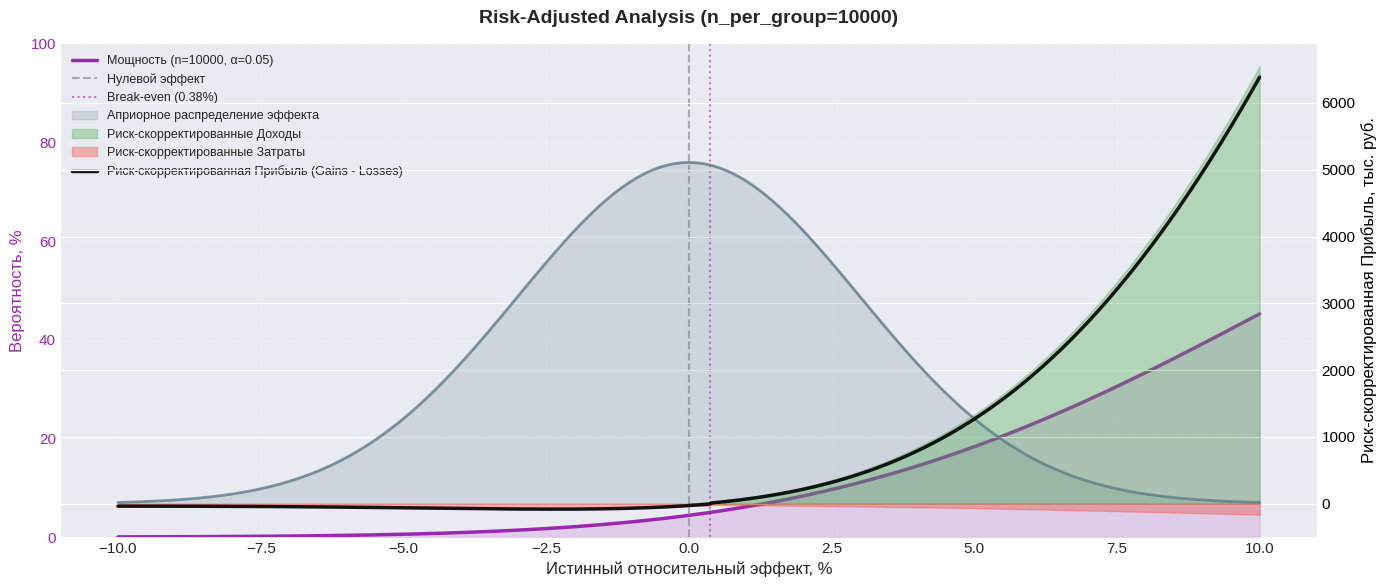


=== Ключевые метрики ===
Ожидаемый эффект (априорный): 0.000%
Ожидаемые риск-скорректированные доходы (Gains): 252,924 руб.
Ожидаемые риск-скорректированные затраты (Losses): 231,883 руб.
Риск-скорректированная прибыль (Net): 21,042 руб.
Risk/Reward ratio: 1.091


In [8]:
def risk_reward_components(
    effect_grid: np.ndarray, # сетка эффектов
    density: np.ndarray, # распределение эффектов
    decision_prob: np.ndarray, # вероятность раскатки
    break_even_effect: float, # точка безубыточности
    weekly_revenue: float, # недельная выручка
    test_duration_weeks: float, # длительность теста
    effect_horizon_weeks: float, # горизонт длительности эффекта
    fixed_test_cost: float, # фиксированные затраты на тестировании
    implementation_cost: float, # стоимость внедрения
    rollback_cost: float, # стоимость отката
    monthly_maintenance_delta: float, # стоимость поддержки решения
    effect_horizon_months: float # длительность поддержки
):
    """
    Рассчитывает риск-скорректированные выгоды и издержки эксперимента.
    """

    # Эффект во время теста (половина пользователей видит treatment)
    execution_value = weekly_revenue * effect_grid * test_duration_weeks * 0.5

    # Эффект после внедрения (с учётом вероятности внедрения)
    post_implementation_value = weekly_revenue * effect_grid * effect_horizon_weeks * decision_prob

    # Затраты на поддержку (только если вариант внедрён)
    maintenance_cost_total = monthly_maintenance_delta * effect_horizon_months * decision_prob

    # Выгоды (только положительная часть)
    gains = np.maximum(execution_value, 0) + np.maximum(post_implementation_value, 0)

    # Потери (отрицательная часть + затраты на внедрение/откат)
    losses = (
        np.maximum(-execution_value, 0)
        + np.maximum(-post_implementation_value, 0)
        + implementation_cost * decision_prob
        + maintenance_cost_total
        + rollback_cost * decision_prob * (effect_grid < break_even_effect)
    )

    # Интегрирование по распределению ожидаемых эффектов
    expected_gain = np.trapezoid(gains * density, effect_grid)
    expected_loss = fixed_test_cost + np.trapezoid(losses * density, effect_grid)

    return expected_gain, expected_loss, gains, losses

def plot_risk_adjusted_analysis(
    effect_grid: np.ndarray,
    density: np.ndarray,
    break_even_effect: float,
    weekly_revenue: float,
    test_duration_weeks: float,
    effect_horizon_weeks: float,
    fixed_test_cost: float,
    implementation_cost: float,
    rollback_cost: float,
    monthly_maintenance_delta: float,
    effect_horizon_months: float,
    baseline_cr: float,
    n_per_group: int,
    alpha: float = 0.05
):
    """
    Строит график с двумя осями:
    - Левая ось (0-100%): функция мощности (вероятность обнаружить эффект > break-even)
    - Правая ось (рубли): probability-adjusted revenue (gains - losses)
    """

    # 1. Рассчитываем вероятность внедрения (мощность)
    decision_prob = implementation_probability(
        p_control=baseline_cr,
        relative_effect=effect_grid,
        break_even_effect=break_even_effect,
        n_per_group=n_per_group,
        alpha=alpha
    )

    # 2. Получаем интегрированные значения и ряды gains/losses
    expected_gain, expected_loss, gains, losses = risk_reward_components(
        effect_grid=effect_grid,
        density=density,
        decision_prob=decision_prob,
        break_even_effect=break_even_effect,
        weekly_revenue=weekly_revenue,
        test_duration_weeks=test_duration_weeks,
        effect_horizon_weeks=effect_horizon_weeks,
        fixed_test_cost=fixed_test_cost,
        implementation_cost=implementation_cost,
        rollback_cost=rollback_cost,
        monthly_maintenance_delta=monthly_maintenance_delta,
        effect_horizon_months=effect_horizon_months
    )

    # 3. Net revenue (риск-скорректированная прибыль) - массив, поэлементная разница
    prob_adjusted_revenue = gains - losses

    # 4. Мощность (для левой оси) - в процентах
    power_pct = decision_prob * 100

    # 5. Нормализация априорного распределения для визуализации
    density_norm = density / np.trapezoid(density, effect_grid)
    max_revenue_abs = np.max(np.abs(prob_adjusted_revenue))
    if max_revenue_abs > 0:
        density_scaled = density_norm * (max_revenue_abs / density_norm.max()) * 0.8
    else:
        density_scaled = density_norm * 0.8

    # 6. Создание графика
    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Левая ось (вероятность 0-100% для мощности)
    ax1.set_xlabel("Истинный относительный эффект, %", fontsize=12)
    ax1.set_ylabel("Вероятность, %", color=C_ALT, fontsize=12)
    ax1.tick_params(axis="y", labelcolor=C_ALT)
    ax1.set_ylim(0, 100)

    # График мощности (левая ось)
    ax1.plot(effect_grid * 100, power_pct,
             color=C_ALT, linestyle="-", linewidth=2.5,
             label=f"Мощность (n={n_per_group}, α={alpha})")
    ax1.fill_between(effect_grid * 100, 0, power_pct,
                     alpha=0.15, color=C_ALT)

    # Правая ось (деньги)
    ax2 = ax1.twinx()
    ax2.set_ylabel("Риск-скорректированная Прибыль, тыс. руб.", color="black", fontsize=12)
    ax2.tick_params(axis="y", labelcolor="black")
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000:.0f}'))

    effect_pct = effect_grid * 100

    # Априорное распределение
    ax2.fill_between(effect_pct, 0, density_scaled,
                     alpha=0.2, color=C_NEUT, label="Априорное распределение эффекта")
    ax2.plot(effect_pct, density_scaled,
             color=C_NEUT, linewidth=2, alpha=0.8, label="_"*20)

    # Закраска gains и losses
    gains_masked = np.where(gains > 0, gains, np.nan)
    losses_masked = np.where(losses > 0, -losses, np.nan)

    ax2.fill_between(effect_pct, 0, gains_masked,
                     alpha=0.35, color=C_GAIN, label="Риск-скорректированные Доходы")
    ax2.fill_between(effect_pct, 0, losses_masked,
                     alpha=0.35, color=C_LOSS, label="Риск-скорректированные Затраты")

    # Чёрная линия для net revenue (массив, поэлементная разница gains - losses)
    ax2.plot(effect_pct, prob_adjusted_revenue,
             color="black", linewidth=2.5, alpha=0.9, label="Риск-скорректированная Прибыль (Gains - Losses)")

    # Вертикальные линии
    ax1.axvline(0, linestyle="--", color="gray", linewidth=1.5, alpha=0.6, label="Нулевой эффект")
    ax1.axvline(break_even_effect * 100, linestyle=":", color=C_ALT,
                linewidth=1.5, alpha=0.6, label=f"Break-even ({break_even_effect*100:.2f}%)")

    # Объединённая легенда
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

    ax1.set_title(f"Risk-Adjusted Analysis (n_per_group={n_per_group})",
                  fontsize=14, fontweight='bold', pad=15)

    ax1.grid(True, alpha=0.2, linestyle='--')
    ax1.set_xlim(-11, 11)

    # Убираем лишние границы
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax2.spines['top'].set_visible(False)

    plt.tight_layout()
    plt.show()

    # Вывод метрик (используем интегрированные значения)
    print("\n=== Ключевые метрики ===")
    density_norm = density / np.trapezoid(density, effect_grid)
    expected_effect = np.trapezoid(effect_grid * density_norm, effect_grid)

    print(f"Ожидаемый эффект (априорный): {expected_effect*100:.3f}%")
    print(f"Ожидаемые риск-скорректированные доходы (Gains): {expected_gain:,.0f} руб.")
    print(f"Ожидаемые риск-скорректированные затраты (Losses): {expected_loss:,.0f} руб.")
    print(f"Риск-скорректированная прибыль (Net): {expected_gain - expected_loss:,.0f} руб.")
    if expected_loss > 0:
        print(f"Risk/Reward ratio: {expected_gain/expected_loss:.3f}")


n_example = 5_000

total_n_example = 2 * n_example # итоговая выборка
test_duration_weeks = total_n_example / weekly_users # длительность эксперимента
test_duration_days = test_duration_weeks * 7 # длительность эксперимента в днях

plot_risk_adjusted_analysis(
    effect_grid=effect_grid,
    density=density,
    break_even_effect=fixed_cost_break_even,
    weekly_revenue=weekly_revenue,
    test_duration_weeks=test_duration_weeks,
    effect_horizon_weeks=effect_horizon_weeks,
    fixed_test_cost=fixed_test_cost,
    implementation_cost=implementation_cost,
    rollback_cost=rollback_cost,
    monthly_maintenance_delta=monthly_maintenance_delta,
    effect_horizon_months=effect_horizon_months,
    baseline_cr=baseline_cr,
    n_per_group=n_example * 2,
    alpha=alpha_example
)

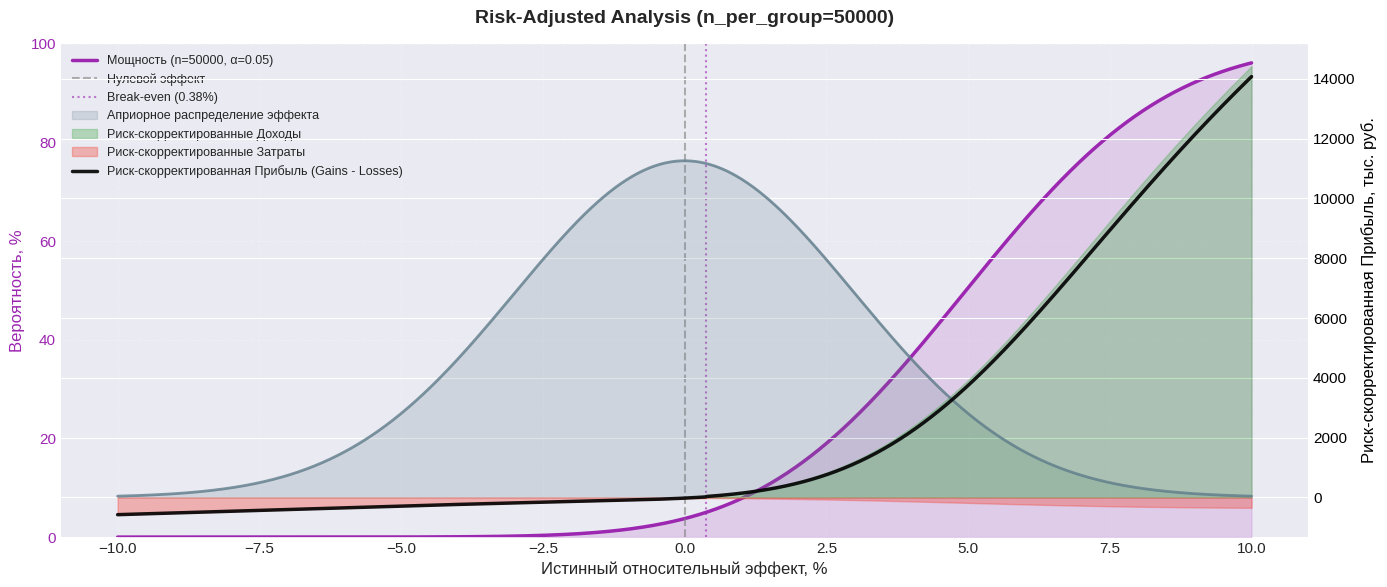


=== Ключевые метрики ===
Ожидаемый эффект (априорный): 0.000%
Ожидаемые риск-скорректированные доходы (Gains): 675,412 руб.
Ожидаемые риск-скорректированные затраты (Losses): 297,346 руб.
Риск-скорректированная прибыль (Net): 378,065 руб.
Risk/Reward ratio: 2.271


In [14]:
plot_risk_adjusted_analysis(
    effect_grid=effect_grid,
    density=density,
    break_even_effect=fixed_cost_break_even,
    weekly_revenue=weekly_revenue,
    test_duration_weeks=test_duration_weeks,
    effect_horizon_weeks=effect_horizon_weeks,
    fixed_test_cost=fixed_test_cost,
    implementation_cost=implementation_cost,
    rollback_cost=rollback_cost,
    monthly_maintenance_delta=monthly_maintenance_delta,
    effect_horizon_months=effect_horizon_months,
    baseline_cr=baseline_cr,
    n_per_group=n_example * 10,
    alpha=alpha_example
)

Наиболее **важным следствием** возможности вычисления соотношения риска и выгоды является то, что путем итеративной корректировки размера выборки и порогового значения значимости можно получить оптимальный набор параметров. Они оптимальны в том смысле, что максимизируют соотношение риска и выгоды, и, следовательно, приводят к оптимальному по ROI тесту.

Учет конкретных обстоятельств каждого эксперимента позволяет избежать «универсального» решения, заключающегося в использовании традиционного 95% доверительного интервала (уровень значимости 0,05) и расчете размера выборки для достижения 80% мощности для более или менее произвольно выбранного минимального интересующего эффекта. Это позволяет нам выбрать комбинацию размера выборки и порога значимости (и, следовательно, мощности и MEI), при которой A/B-тест оказывает положительное влияние на финансовые результаты бизнеса, независимо от его исхода.

#### 5.2.3.2 Замечания при сложных ситуациях

1) Расчеты усложняются при использовании схемы последовательного мониторинга, поскольку в этом случае продолжительность теста и период эксплуатации не фиксированы, а зависят от неизвестного истинного значения интересующего параметра $θ^*$. Имея распределение ожиданий, можно рассчитать среднюю продолжительность и использовать ее для оценки дохода, подверженного риску во время и после тестирования, что делает расчеты возможными.

2) Увеличение количества вариантов вводит дополнительные допущения при расчете размера выборки и в некоторых случаях может потребовать введения отдельного распределения ожиданий для каждого тестируемого варианта. Это еще больше усложняет математику, но логика вычислений остается той же.

## 6. Поиск оптимального α

Следующим шагом рассмотрим, как меняется ожидаемый финансовый результат эксперимента при разных значениях уровня значимости и размера выборки. Для этого для каждой пары параметров будут рассчитаны риск-скорректированные выгоды и издержки, после чего можно будет сравнить различные дизайны теста по их ожидаемому соотношению выгоды и риска.

In [15]:
alpha_grid = np.linspace(0.01, 1.0, 20)
n_grid = np.arange(1_000, 100_001, 5_000)

results = []

for alpha_val in alpha_grid:
    for n_val in n_grid:
        decision_prob_vals = implementation_probability(
            p_control=baseline_cr,
            relative_effect=effect_grid,
            break_even_effect=fixed_cost_break_even,
            n_per_group=n_val,
            alpha=alpha_val
        )

        total_n = 2 * n_val
        test_duration_weeks = total_n / weekly_users

        expected_gain, expected_loss, _, _ = risk_reward_components(
            effect_grid=effect_grid,
            density=density,
            decision_prob=decision_prob_vals,
            break_even_effect=fixed_cost_break_even,
            weekly_revenue=weekly_revenue,
            test_duration_weeks=test_duration_weeks,
            effect_horizon_weeks=effect_horizon_weeks,
            fixed_test_cost=fixed_test_cost,
            implementation_cost=implementation_cost,
            rollback_cost=rollback_cost,
            monthly_maintenance_delta=monthly_maintenance_delta,
            effect_horizon_months=effect_horizon_months
        )

        ratio = expected_gain / expected_loss if expected_loss > 0 else np.nan
        net_value = expected_gain - expected_loss
        roi = net_value / expected_loss if expected_loss > 0 else np.nan

        results.append({
            "Статистическая значимость": round(alpha_val, 4),
            "Пользователей на группу": int(n_val),
            "Всего пользователей": int(total_n),
            "Длительность теста (дней)": round(test_duration_weeks * 7, 1),
            "Ожидаемые риск-скорректированные доходы (Gains)": round(expected_gain, 0),
            "Ожидаемые риск-скорректированные затраты (Losses)": round(expected_loss, 0),
            "Risk/Reward Ratio": round(ratio, 3),
            "Риск-скорректированная прибыль (Net)": round(net_value, 0),
            "ROI": round(roi, 3)
        })


results_df = pd.DataFrame(results)

top_results = results_df.sort_values("Risk/Reward Ratio", ascending=False)
top_results.head(5)

,Статистическая значимость,Пользователей на группу,Всего пользователей,Длительность теста (дней),Ожидаемые риск-скорректированные доходы (Gains),Ожидаемые риск-скорректированные затраты (Losses),Risk/Reward Ratio,Риск-скорректированная прибыль (Net),ROI
99,0.2184,96000,192000,26.9,1330371.0,388593.0,3.424,941777.0,2.424
79,0.1663,96000,192000,26.9,1245811.0,364794.0,3.415,881017.0,2.415
98,0.2184,91000,182000,25.5,1313087.0,385763.0,3.404,927325.0,2.404
78,0.1663,91000,182000,25.5,1226607.0,361266.0,3.395,865341.0,2.395
119,0.2705,96000,192000,26.9,1398678.0,413206.0,3.385,985472.0,2.385


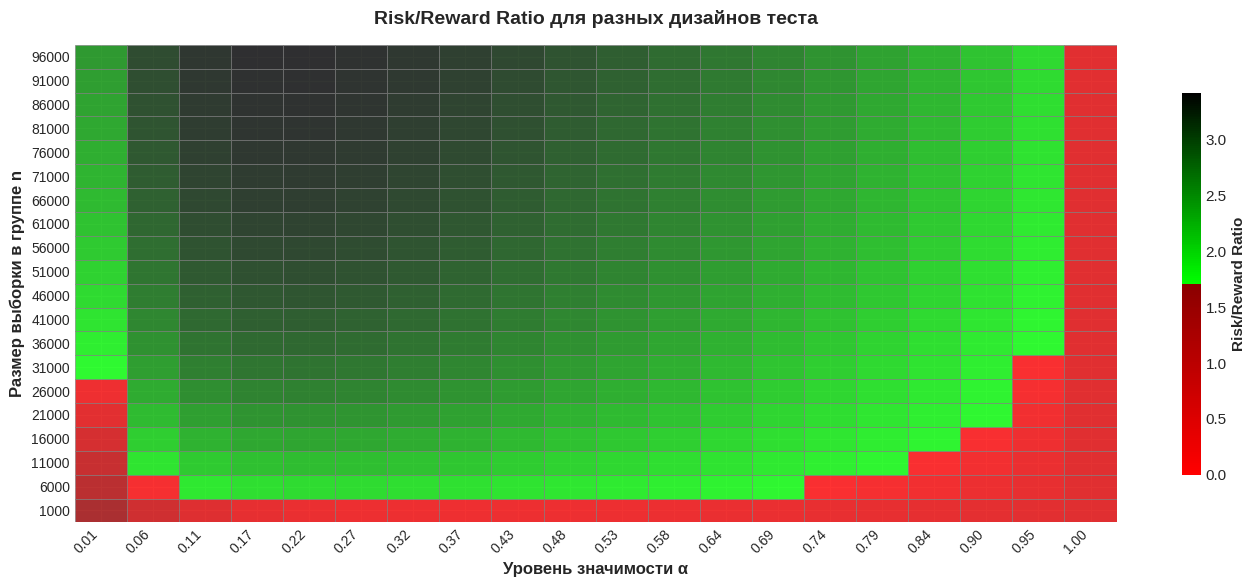

In [16]:
pivot_ratio = results_df.pivot(index="Пользователей на группу", columns="Статистическая значимость", values="Risk/Reward Ratio")

fig, ax = plt.subplots(figsize=(14, 6))

# Создаём массив цветов
ratio_values = pivot_ratio.values
colors = np.zeros_like(ratio_values, dtype=object)

# Нормализация для красного канала (значения от 0 до 1)
red_norm = 1 - (ratio_values / 1)
red_norm = np.clip(red_norm, 0, 1)

# Нормализация для зелёного канала
green_norm = (ratio_values - 1) / (ratio_values.max() - 1) if ratio_values.max() > 1 else np.zeros_like(ratio_values)
green_norm = np.clip(green_norm, 0, 1)

# Применяем цвета
for i in range(ratio_values.shape[0]):
    for j in range(ratio_values.shape[1]):
        val = ratio_values[i, j]
        if np.isnan(val):
            colors[i, j] = 'lightgray'
        elif val < 1:
            intensity = int(139 + (255 - 139) * (1 - red_norm[i, j]))
            colors[i, j] = f'#{intensity:02x}{0:02x}{0:02x}'
        else:
            intensity = int(255 - (255 - 0) * green_norm[i, j])
            colors[i, j] = f'#{0:02x}{intensity:02x}{0:02x}'

# Отрисовка heatmap
for i in range(ratio_values.shape[0]):
    for j in range(ratio_values.shape[1]):
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=colors[i, j], edgecolor='gray', linewidth=0.5, alpha=0.8))

# Настройка осей
ax.set_xlim(-0.5, ratio_values.shape[1] - 0.5)
ax.set_ylim(-0.5, ratio_values.shape[0] - 0.5)

ax.set_xticks(np.arange(len(pivot_ratio.columns)))
ax.set_xticklabels([f"{x:.2f}" for x in pivot_ratio.columns], rotation=45, ha='right', fontsize=10)
ax.set_yticks(np.arange(len(pivot_ratio.index)))
ax.set_yticklabels(pivot_ratio.index, fontsize=10)

ax.set_xlabel("Уровень значимости α", fontsize=12, fontweight='semibold')
ax.set_ylabel("Размер выборки в группе n", fontsize=12, fontweight='semibold')
ax.set_title("Risk/Reward Ratio для разных дизайнов теста", fontsize=14, fontweight='bold', pad=15)

# Добавляем цветовую шкалу (градусник) без импорта Normalize
from matplotlib.patches import Rectangle
from matplotlib.cm import ScalarMappable

# Создаём кастомную цветовую карту
cmap_colors = []
for val in np.linspace(0, 1, 100):
    intensity = int(139 + (255 - 139) * (1 - val))
    cmap_colors.append(f'#{intensity:02x}{0:02x}{0:02x}')
for val in np.linspace(1, ratio_values.max(), 100):
    green_norm_val = (val - 1) / (ratio_values.max() - 1) if ratio_values.max() > 1 else 0
    intensity = int(255 - (255 - 0) * green_norm_val)
    cmap_colors.append(f'#{0:02x}{intensity:02x}{0:02x}')

from matplotlib.colors import ListedColormap
custom_cmap = ListedColormap(cmap_colors)

# Создаём ScalarMappable для colorbar
sm = ScalarMappable(cmap=custom_cmap)
sm.set_array(np.linspace(0, ratio_values.max(), len(cmap_colors)))

# Добавляем colorbar
cbar = plt.colorbar(sm, ax=ax, shrink=0.8, pad=0.05)
cbar.set_label("Risk/Reward Ratio", fontsize=11, fontweight='semibold')

# Убираем лишние границы
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.show()

## 7. Проведение тестирования $\alpha$ = 0.5 ?

### 7.1 Провокационный вопрос

Автор задаёт провокационный вопрос: **«Что если установить уровень значимости $\alpha$ = 0.5?»**

На первый взгляд, это звучит абсурдно. В научной среде такой порог считается неприемлемым — это означало бы, что мы готовы ошибаться в каждом втором случае, когда отвергаем нулевую гипотезу. Интуитивно кажется, что тест с таким параметром просто «подбрасывание монетки», и его Risk/Reward Ratio должен быть около 1/1.

**Но так ли это на самом деле?**

Ошибка в рассуждениях кроется в том, что мы неявно предполагаем симметричность последствий. «Монетка» подразумевает, что вероятность ошибиться в любую сторону одинакова. Однако это не так!

- **Для положительных эффектов** (вариант действительно лучше): мощность растёт очень быстро даже при небольших эффектах. Тест с высокой вероятностью обнаружит реальное улучшение.
- **Для отрицательных эффектов** (вариант хуже контроля): мощность стремится к нулю. Тест **почти никогда** не ошибочно укажет на «победу» варианта, который на самом деле значительно хуже.

### 7.2 Ассиметричность функции мощности

Асимметрия функции мощности — это не случайность и не ошибка в коде, а **фундаментальное свойство**, вытекающее из того, как мы формулируем статистические гипотезы и какую бизнес-задачу решаем.

> **Коротко:** мы используем двусторонний статистический тест для ответа на односторонний бизнес-вопрос («Улучшит ли вариант B метрику?»). Эта нестыковка и порождает асимметрию.

В основе A/B-теста лежит сравнение двух пропорций — конверсии в контрольной (p₀) и тестовой (p₁) группах. Тестовая статистика z-теста:

$$
z = \frac{p_1 - p_0}{SE}, \quad \text{где} \quad SE = \sqrt{\frac{p_0(1-p_0)}{n} + \frac{p_1(1-p_1)}{n}}
$$

Если верна нулевая гипотеза $H_0$, то распределение $z$-статистики — стандартное нормальное $N(0, 1)$.

Если верна альтернативная гипотеза $H_1$, то распределение $z$-статистики **сдвигается**. Оно центрировано вокруг **параметра нецентральности (NCP)**:

$$
\text{NCP} = \frac{|p_1 - p_0|}{SE}
$$


Для двустороннего теста $H_0$ отвергается, если $z$ попадает в один из двух «хвостов»: $z < -z_{1-α/2}$ или $z > z_{1-α/2}$. Мощность тогда равна:

$$
\text{Power} = P(z > z_{1-α/2} \mid H_1) + P(z < -z_{1-α/2} \mid H_1)
$$

На практике, когда мы хотим обнаружить именно **улучшение** (положительный эффект), распределение $H_1$ сдвинуто вправо (NCP > 0). Вероятность попасть в левый хвост исчезающе мала. Используя приближение $\Phi_{NCP}(x) ≈ \Phi(x - NCP) $, получаем:

$$
\text{Power} \approx 1 - \Phi(z_{1-α/2} - \text{NCP})
$$

 Теперь рассмотрим 2 случая:

- Если у нас имеет место **положительный эффект ($p_1 > p_0$)**, то NCP > 0, тогда ($z_{1-α/2}$ - NCP) будет отрицательно, а следовательно, $\Phi(\cdot)$ уменьшается, а мощность стремится к 1.
- При **отрицательном эффекте ($p_1 < p_0$):** мы по-прежнему используем ту же формулу, но теперь мы отвечаем на вопрос: какова вероятность **ошибочно** показать значимое улучшение, когда произошло ухудшение? Распределение сдвинуто влево, вероятность попасть в правый хвост уменьшается при увеличении сдвига, значит → мощность стремится к 0.

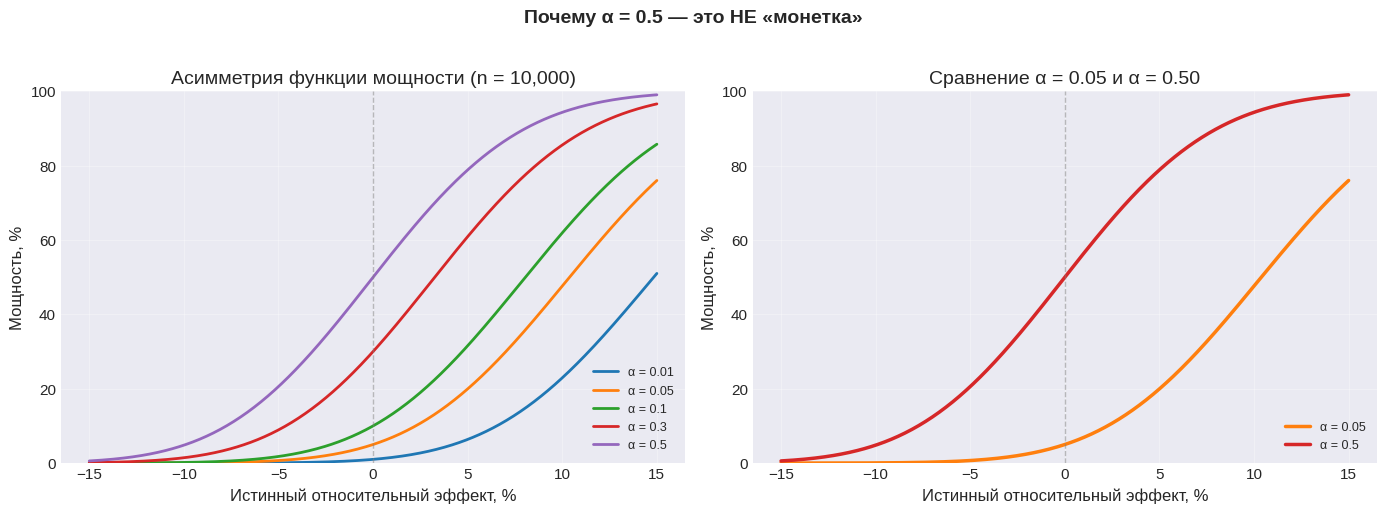

In [13]:
# ============================================================================
# 1. Асимметрия функции мощности
# ============================================================================

n_demo = 10_000
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Левый график: мощность для разных α
ax1 = axes[0]
effects_plot = np.linspace(-0.15, 0.15, 500)

alphas_plot = [0.01, 0.05, 0.10, 0.30, 0.50]
colors_plot = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for alpha_val, color in zip(alphas_plot, colors_plot):
    power_vals = implementation_probability(
        p_control=baseline_cr,
        relative_effect=effects_plot,
        break_even_effect=0.0,
        n_per_group=n_demo,
        alpha=alpha_val
    )
    ax1.plot(effects_plot * 100, power_vals * 100,
             color=color, linewidth=2, label=f"α = {alpha_val}")

ax1.axvline(0, linestyle="--", color="gray", alpha=0.5, linewidth=1)
ax1.set_xlabel("Истинный относительный эффект, %")
ax1.set_ylabel("Мощность, %")
ax1.set_title(f"Асимметрия функции мощности (n = {n_demo:,})")
ax1.legend(loc="lower right", fontsize=9)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 100)

# Правый график: сравнение α = 0.05 и α = 0.50
ax2 = axes[1]

for alpha_val, color in zip([0.05, 0.50], ['#ff7f0e', '#d62728']):
    power_vals = implementation_probability(
        p_control=baseline_cr,
        relative_effect=effects_plot,
        break_even_effect=0.0,
        n_per_group=n_demo,
        alpha=alpha_val
    )
    ax2.plot(effects_plot * 100, power_vals * 100,
             color=color, linewidth=2.5, label=f"α = {alpha_val}")

ax2.axvline(0, linestyle="--", color="gray", alpha=0.5, linewidth=1)
ax2.set_xlabel("Истинный относительный эффект, %")
ax2.set_ylabel("Мощность, %")
ax2.set_title("Сравнение α = 0.05 и α = 0.50")
ax2.legend(loc="lower right", fontsize=9)
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 100)

plt.suptitle("Почему α = 0.5 — это НЕ «монетка»", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Левый график (Асимметрия функции мощности)**

Левый график демонстрирует, как вероятность обнаружить эффект (мощность) зависит от истинного размера эффекта. Разные цветные линии — это разные уровни значимости $\alpha$.

**Ключевое наблюдение — резкая асимметрия:**
- **Слева от нуля (отрицательные эффекты, вариант хуже контроля):** все линии стремятся к нулю. Чем сильнее ухудшение, тем меньше вероятность ошибочно назвать вариант победителем.
- **Справа от нуля (положительные эффекты, вариант лучше контроля):** все линии быстро растут. Даже при мягком α = 0.5, при эффекте +3% мощность уже достигает ~85%.
- **В точке 0 (нулевой эффект):** мощность равна α — вероятности ложного срабатывания.

___

**Правый график (Сравнение α = 0.05 и α = 0.50)**

Правый график фокусируется на двух ключевых значениях:

| Зона | α = 0.05 | α = 0.50 | Что это значит |
|------|----------|----------|----------------|
| **Ухудшение на 5%** | ~0% | ~0% | Оба теста никогда не скажут «победа» для плохого варианта |
| **Ухудшение на 3%** | ~0.1% | ~0.5% | Риск ошибиться минимален даже при α = 0.5 |
| **Нулевой эффект** | 5% | 50% | Только здесь α = 0.5 даёт 50% ошибок |
| **Улучшение на 3%** | ~50% | ~85% | При α = 0.5 тест ЛУЧШЕ обнаруживает улучшения! |
| **Улучшение на 5%** | ~85% | ~99% | Оба теста хорошо работают |

**Главный вывод:** страшный для бизнеса сценарий — внедрение плохого варианта — остаётся крайне маловероятным даже при $\alpha$ = 0.5. Асимметрия защищает нас от главного риска, позволяя при этом проводить более короткие и дешёвые тесты.

## 8. Ограничения модели


#### 8.1 Кратко

1. **Упрощённое распределение ожиданий** — на практике распределение может быть сложнее и асимметрично.
2. **Фиксированный горизонт эффекта** — эффект может затухать со временем (novelty effects).
3. **Игнорирование долгосрочных эффектов** — некоторые изменения влияют на LTV, бренд, лояльность.
4. **Не учтены альтернативные издержки** — время и ресурсы на тест могли быть использованы иначе.
5. **Проблема референтного класса** — выбор prior распределения субъективен.

Тем не менее, представленный подход даёт практический фреймворк для принятия решений о дизайне A/B-тестов с учётом бизнес-контекста.

#### 8.2 Развернуто

Как и в любом алгоритме, расчет соотношения риска и выгоды будет настолько точным, насколько точны исходные данные. Если распределение ожиданий сильно искажено, или если определенные затраты недооценены, а выгоды преувеличены, рассчитанная оптимальная с точки зрения ROI модель на самом деле не будет оптимальной. Аналогично, если ожидаемая продолжительность периода эксплуатации завышена или занижена, то расчет будет неверным. Очевидно, существует «достаточно хороший» уровень оценки, который уравновешивает сложность получения точных оценок и их полезность.

Однако при применении этой модели соотношения риска и выгоды для разработки оптимальных с точки зрения ROI A/B-тестов необходимо учитывать определенные ограничения.

Первое, что также является препятствием для применения A/B-тестов в целом, — это **долгосрочные эффекты**. Такие эффекты, как с точки зрения затрат, так и выгод, просто трудно измерить с помощью краткосрочных экспериментов, учитывая изменчивый характер веб-сайтов, технологий, ожиданий пользователей, рыночных сил и других факторов. Одно из предположений в предлагаемых здесь расчетах заключается в том, что результат будет примерно одинаковым на протяжении всего периода эксплуатации. Однако это не обязательно так, поскольку эффекты новизны в обоих направлениях исчезают, а изменения обстоятельств, совершенно внешних по отношению к веб-сайту, влияют на будущее поведение пользователей. Любая оценка продолжительности эксплуатации реализованного варианта также неизбежно является неопределенной.

Во-вторых, следует рассмотреть малоизученный эффект, а именно **постоянное внесение изменений в пользовательский опыт**. Продукты, которые проходят множество A/B-тестирований, могут страдать от этого факта независимо от результатов A/B-тестирования. Если сегодня главная страница выглядит одним образом, через месяц — другим, затем проходит еще месяц, и она возвращается к исходному виду, то же самое происходит с корзиной покупок, процессом регистрации и т. д., разве это не может оказать негативное влияние на пользователей? Если такие эффекты существуют, будут ли они более выражены на сайтах, которые пользователи часто посещают, таких как новостные сайты, социальные сети и другие ресурсы с высокой частотой повторных посещений в относительно короткие сроки, или же они будут более неожиданными для пользователей веб-сайтов с менее частыми посещениями?

Мне неизвестны ответы на эти вопросы или серьезные исследования по этой теме в целом, но это потенциальное ограничение, о котором следует помнить.

Наконец, существует общая **альтернативная стоимость A/B-тестирования**. Что, если время и деньги, потраченные на A/B-тестирование, будут инвестированы во что-то совершенно другое? Некоторым компаниям может быть выгоднее отказаться от A/B-тестирования и пойти на больший риск, направив ресурсы в другое русло. A/B-тестирование — это средство достижения цели, и если эта цель может быть достигнута другими способами, не подвергая бизнес чрезмерному риску из-за неправильных решений, почему бы этого не сделать?

Расчет предельного улучшения соотношения риска и вознаграждения имеет первостепенное значение при ответе на вопрос об альтернативной стоимости. Это показывает, насколько лучше было бы, если бы мы решили проводить тестирование, а не просто внедрять все, что считается подлежащим тестированию. Хотя это и не дает полной картины, это полезное сравнение.